# Chapter 1: Fundamentals of Computational Intelligence and Machine Learning

This notebook collects the runnable examples of *Chapter 1: Fundamentals of Computational Intelligence and Machine Learning* from the textbook *Computational and Biological Intelligence* (A. Movasagh). Run the cells in order; each example is independent unless noted. Figures are also saved as PNG files in this folder.

## Learning objectives

After working through this notebook you should be able to:

- define computational intelligence and its main branches and name its applications in medicine.
- explain the difference between supervised, unsupervised, and reinforcement learning.
- distinguish classification problems from regression problems and build a simple model for each in scikit-learn.
- describe the stages of the roadmap of a machine learning project.
- split data correctly into training, validation, and test sets.
- recognize underfitting and overfitting using error curves and apply early stopping.


In [1]:
%matplotlib inline

## Example 1.1: Binary classification with logistic regression

Script version: `example_1_1.py`

Accuracy on training data: 0.98
Predicted class for (0.5, 0.5): 1
Class probabilities: [[0.173 0.827]]


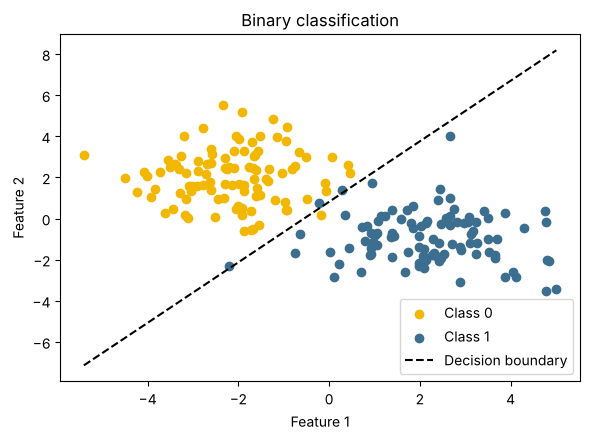

In [2]:
# Example 1.1: Binary classification with logistic regression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.linear_model import LogisticRegression
 
# 1) Create synthetic data: two groups of points in the plane
X, y = make_blobs(n_samples=200, centers=[(-2, 2), (2, -1)],
                  cluster_std=1.3, random_state=42)
 
# 2) Train the classifier
model = LogisticRegression()
model.fit(X, y)
 
# 3) Evaluate and predict for a new point
print("Accuracy on training data:", round(model.score(X, y), 3))
new_point = np.array([[0.5, 0.5]])
print("Predicted class for (0.5, 0.5):", model.predict(new_point)[0])
print("Class probabilities:", model.predict_proba(new_point).round(3))
 
# 4) Plot the data and the decision boundary (separating line)
w1, w2 = model.coef_[0]
b = model.intercept_[0]
xs = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
plt.figure(figsize=(6, 4.5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="#F2B701", label="Class 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="#3C6E8F", label="Class 1")
plt.plot(xs, -(w1 * xs + b) / w2, "k--", label="Decision boundary")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.legend(); plt.title("Binary classification")
plt.tight_layout(); plt.savefig("fig1_1.png", dpi=300)

## Example 1.2: Predicting blood pressure from age with linear regression

Script version: `example_1_2.py`

Slope (w): 0.693
Intercept (b): 90.844
Predicted pressure at age 50: 125.5
MSE: 36.65


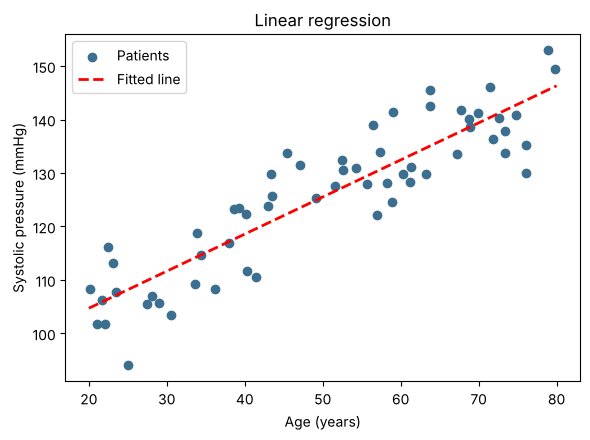

In [3]:
# Example 1.2: Simple linear regression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
 
rng = np.random.default_rng(0)
# Hypothetical data: patient age (years) and systolic blood pressure (mmHg)
age = rng.uniform(20, 80, 60).reshape(-1, 1)
pressure = 90 + 0.7 * age.ravel() + rng.normal(0, 6, 60)
 
model = LinearRegression()
model.fit(age, pressure)
 
print("Slope (w):", round(model.coef_[0], 3))
print("Intercept (b):", round(model.intercept_, 3))
print("Predicted pressure at age 50:", round(model.predict([[50]])[0], 1))
print("MSE:", round(mean_squared_error(pressure, model.predict(age)), 2))
 
xs = np.linspace(20, 80, 100).reshape(-1, 1)
plt.figure(figsize=(6, 4.5))
plt.scatter(age, pressure, c="#3C6E8F", label="Patients")
plt.plot(xs, model.predict(xs), "r--", lw=2, label="Fitted line")
plt.xlabel("Age (years)"); plt.ylabel("Systolic pressure (mmHg)")
plt.legend(); plt.title("Linear regression")
plt.tight_layout(); plt.savefig("fig1_2.png", dpi=300)

## Example 1.3: One problem, two views — regression versus classification

Script version: `example_1_3.py`

In [4]:
# Example 1.3: One problem, two views — regression versus classification
import numpy as np
from sklearn.linear_model import LinearRegression, LogisticRegression
 
rng = np.random.default_rng(1)
today = rng.uniform(0, 40, 300)                     # today's temperature (°C)
tomorrow = 0.9 * today + 2 + rng.normal(0, 2, 300)  # tomorrow's temperature (°C)
X = today.reshape(-1, 1)
 
# View 1: regression — "What will tomorrow's temperature be?"
reg = LinearRegression().fit(X, tomorrow)
print("Regression  -> tomorrow at 28°C today:",
      round(reg.predict([[28]])[0], 1), "°C")
 
# View 2: classification — "Will tomorrow be hot or cold?" (threshold: 25 degrees)
labels = (tomorrow > 25).astype(int)               # 1 = Hot, 0 = Cold
clf = LogisticRegression().fit(X, labels)
pred = clf.predict([[28]])[0]
print("Classification -> tomorrow at 28°C today:",
      "HOT" if pred == 1 else "COLD",
      "| P(hot) =", round(clf.predict_proba([[28]])[0, 1], 2))

Regression  -> tomorrow at 28°C today: 27.3 °C
Classification -> tomorrow at 28°C today: HOT | P(hot) = 0.91


## Example 1.4: Discovering hidden groups with K-Means

Script version: `example_1_4.py`

Cluster sizes: [100, 100, 100]
Cluster centers:
 [[-8.54  5.57]
 [ 9.62  0.56]
 [-1.26  4.39]]


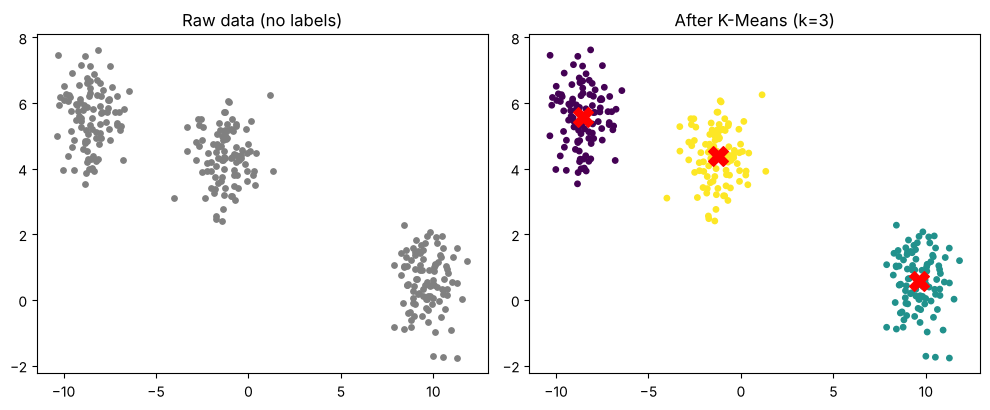

In [5]:
# Example 1.4: Clustering without labels using K-Means
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
 
X, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.9, random_state=7)
 
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
labels = kmeans.fit_predict(X)          # labels are created by the algorithm
 
print("Cluster sizes:", [int((labels == k).sum()) for k in range(3)])
print("Cluster centers:\n", kmeans.cluster_centers_.round(2))
 
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ax[0].scatter(X[:, 0], X[:, 1], c="gray", s=15)
ax[0].set_title("Raw data (no labels)")
ax[1].scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=15)
ax[1].scatter(*kmeans.cluster_centers_.T, c="red", marker="X", s=200)
ax[1].set_title("After K-Means (k=3)")
plt.tight_layout(); plt.savefig("fig1_3.png", dpi=300)

## Example 1.5: Dimensionality reduction of breast cancer data with PCA and LDA

Script version: `example_1_5.py`

Original shape: (569, 30)
PCA shape: (569, 2)
Explained variance ratio: [0.443 0.19 ]
Total kept: 0.632
LDA shape: (569, 1)


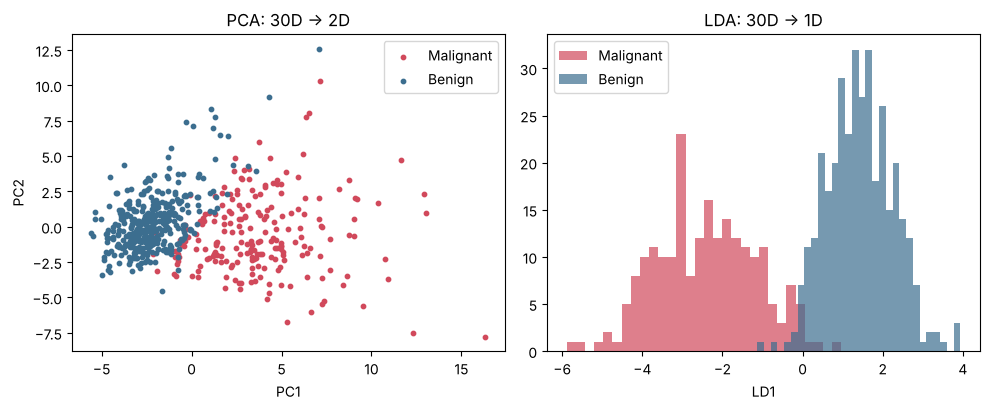

In [6]:
# Example 1.5: Dimensionality reduction of breast cancer data with PCA and LDA
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
 
data = load_breast_cancer()
X, y = data.data, data.target            # 569 samples, 30 features
print("Original shape:", X.shape)
 
X_std = StandardScaler().fit_transform(X)   # feature scaling
 
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)
print("PCA shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Total kept:", round(pca.explained_variance_ratio_.sum(), 3))
 
lda = LinearDiscriminantAnalysis(n_components=1)
X_lda = lda.fit_transform(X_std, y)       # LDA uses the labels y
print("LDA shape:", X_lda.shape)
 
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for cls, color, name in [(0, "#D1495B", "Malignant"), (1, "#3C6E8F", "Benign")]:
    ax[0].scatter(X_pca[y == cls, 0], X_pca[y == cls, 1], s=10, c=color, label=name)
    ax[1].hist(X_lda[y == cls, 0], bins=30, alpha=0.7, color=color, label=name)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].set_title("PCA: 30D -> 2D")
ax[1].set_xlabel("LD1"); ax[1].set_title("LDA: 30D -> 1D")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.savefig("fig1_4.png", dpi=300)

## Example 1.6: Reinforcement learning with Q-Learning

Script version: `example_1_6.py`

In [7]:
# Example 1.6: Reinforcement learning with Q-Learning in a simple corridor
import numpy as np
 
n_states, n_actions = 6, 2     # states 0..5 ; action 0 = left, 1 = right
goal = 5                       # reaching state 5 is rewarded
Q = np.zeros((n_states, n_actions))
alpha, gamma, epsilon = 0.1, 0.9, 0.2
rng = np.random.default_rng(0)
 
for episode in range(500):
    s = 0
    while s != goal:
        # ε-greedy policy: explore sometimes, exploit most of the time
        if rng.random() < epsilon:
            a = int(rng.integers(n_actions))      # explore
        else:
            a = int(np.argmax(Q[s]))              # exploit
        s_next = max(0, s - 1) if a == 0 else min(goal, s + 1)
        r = 1.0 if s_next == goal else -0.01   # reward
        Q[s, a] += alpha * (r + gamma * Q[s_next].max() - Q[s, a])
        s = s_next
 
np.set_printoptions(precision=3, suppress=True)
print("Q-table (rows = states, cols = [left, right]):\n", Q)
print("Learned policy:", ["L" if np.argmax(q) == 0 else "R" for q in Q[:goal]])

Q-table (rows = states, cols = [left, right]):
 [[0.548 0.622]
 [0.549 0.702]
 [0.621 0.791]
 [0.701 0.89 ]
 [0.789 1.   ]
 [0.    0.   ]]
Learned policy: ['R', 'R', 'R', 'R', 'R']


## Example 1.7: Imputing missing values, one-hot encoding, and scaling

Script version: `example_1_7.py`

In [8]:
# Example 1.7: Data preprocessing — missing values, categorical variables, and scaling
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
 
df = pd.DataFrame({
    "age":        [45, 61, np.nan, 38, 72, 55],
    "glucose":    [98, 180, 130, np.nan, 210, 115],
    "sex":        ["F", "M", "M", "F", "F", "M"],
    "smoker":     ["no", "yes", "no", "no", "yes", np.nan],
})
print("Raw data:\n", df, "\n")
print("Missing values per column:\n", df.isna().sum().to_dict(), "\n")
 
numeric, categorical = ["age", "glucose"], ["sex", "smoker"]
prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder()), categorical),
])
X = prep.fit_transform(df)
print("Output columns:", list(prep.get_feature_names_out()))
print("Processed matrix (rounded):\n", np.round(X, 2))
 
scores = np.array([[1.0], [5.0], [9.0]])
print("\nStandardScaler:", StandardScaler().fit_transform(scores).ravel().round(3))
print("MinMaxScaler  :", MinMaxScaler().fit_transform(scores).ravel())

Raw data:
     age  glucose sex smoker
0  45.0     98.0   F     no
1  61.0    180.0   M    yes
2   NaN    130.0   M     no
3  38.0      NaN   F     no
4  72.0    210.0   F    yes
5  55.0    115.0   M    NaN 

Missing values per column:
 {'age': 1, 'glucose': 1, 'sex': 0, 'smoker': 1} 

Output columns: ['num__age', 'num__glucose', 'cat__sex_F', 'cat__sex_M', 'cat__smoker_no', 'cat__smoker_yes']
Processed matrix (rounded):
 [[-0.86 -1.18  1.    0.    1.    0.  ]
 [ 0.61  0.93  0.    1.    0.    1.  ]
 [ 0.06 -0.36  0.    1.    1.    0.  ]
 [-1.5  -0.36  1.    0.    1.    0.  ]
 [ 1.62  1.71  1.    0.    0.    1.  ]
 [ 0.06 -0.74  0.    1.    1.    0.  ]]

StandardScaler: [-1.225  0.     1.225]
MinMaxScaler  : [0.  0.5 1. ]


## Example 1.8: Three-way data split

Script version: `example_1_8.py`

In [9]:
# Example 1.8: Splitting the data into training, validation, and test sets (60/20/20)
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
 
X, y = load_breast_cancer(return_X_y=True)
 
# Step 1: set aside 20% for testing
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
 
# Step 2: from the remaining 80%, one quarter (= 20% of the total) for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)
 
n = len(X)
for name, part in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    print(f"{name:<11}: {len(part):>3} samples ({len(part) / n:.0%})")
print("Benign ratio in train/val/test:",
      round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Train      : 341 samples (60%)
Validation : 114 samples (20%)
Test       : 114 samples (20%)
Benign ratio in train/val/test: 0.628 0.623 0.632


## Example 1.9: Full implementation of a project roadmap

Script version: `example_1_9.py`

In [10]:
# Example 1.9: The complete roadmap of a project — from data to deployment
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
 
# 1) Data collection
X, y = load_breast_cancer(return_X_y=True)
 
# 2) Data splitting (60/20/20)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
X_tr, X_val, y_tr, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=0)
 
# 3) Cleaning/preprocessing + 4) building and training several candidate models
candidates = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN (k=5)":          make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "DecisionTree":       DecisionTreeClassifier(max_depth=4, random_state=0),
}
 
# 5) Evaluate on the validation data and select the best model
scores = {}
for name, m in candidates.items():
    m.fit(X_tr, y_tr)
    scores[name] = m.score(X_val, y_val)
    print(f"{name:<20} validation accuracy = {scores[name]:.3f}")
best = max(scores, key=scores.get)
print("Best model:", best)
 
# 6) Final evaluation — only once — on the test data
final = candidates[best]
print("Test accuracy:", round(final.score(X_test, y_test), 3))
 
# 7) Deployment: save the model and reuse it
joblib.dump(final, "cancer_model.joblib")
loaded = joblib.load("cancer_model.joblib")
print("Prediction for first test sample:", loaded.predict(X_test[:1])[0],
      "| true label:", y_test[0])

LogisticRegression   validation accuracy = 0.991
KNN (k=5)            validation accuracy = 0.974
DecisionTree         validation accuracy = 0.947
Best model: LogisticRegression
Test accuracy: 0.974
Prediction for first test sample: 0 | true label: 0


## Example 1.10: Underfitting, appropriate fit, and overfitting

Script version: `example_1_10.py`

degree= 1 | train MSE=0.116 | validation MSE=0.164
degree= 4 | train MSE=0.018 | validation MSE=0.099
degree=15 | train MSE=0.009 | validation MSE=12591.153


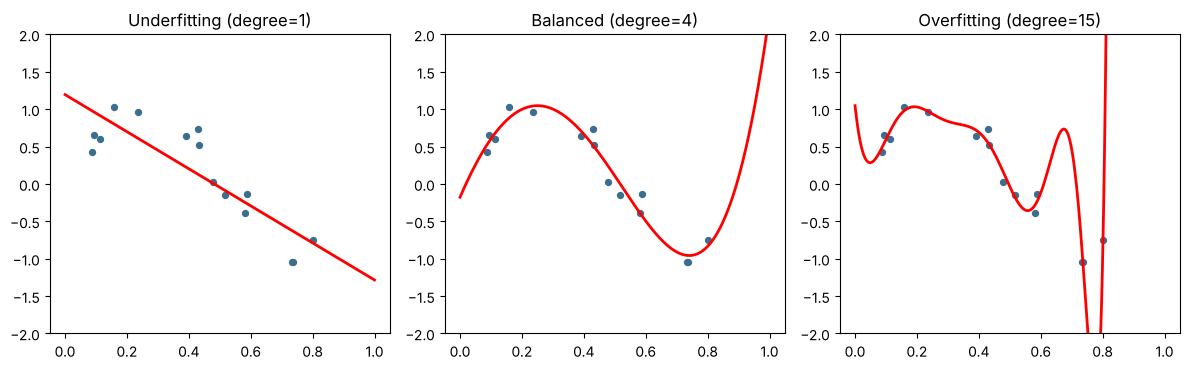

In [11]:
# Example 1.10: Underfitting, appropriate fit, and overfitting with polynomial regression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
 
rng = np.random.default_rng(3)
x = np.sort(rng.uniform(0, 1, 15))
y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, 15)      # training data
x_val = np.sort(rng.uniform(0, 1, 30))
y_val = np.sin(2 * np.pi * x_val) + rng.normal(0, 0.2, 30)  # validation data
 
xs = np.linspace(0, 1, 300)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, degree, title in zip(axes, [1, 4, 15],
                             ["Underfitting", "Balanced", "Overfitting"]):
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(x.reshape(-1, 1), y)
    tr = mean_squared_error(y, model.predict(x.reshape(-1, 1)))
    va = mean_squared_error(y_val, model.predict(x_val.reshape(-1, 1)))
    print(f"degree={degree:>2} | train MSE={tr:.3f} | validation MSE={va:.3f}")
    ax.scatter(x, y, c="#3C6E8F", s=18, label="train")
    ax.plot(xs, model.predict(xs.reshape(-1, 1)), "r", lw=2)
    ax.set_ylim(-2, 2); ax.set_title(f"{title} (degree={degree})")
plt.tight_layout(); plt.savefig("fig1_5.png", dpi=300)

## Example 1.11: The error curve and early stopping

Script version: `example_1_11.py`

Best epoch (minimum validation error): 675
Validation MSE at best epoch: 0.0757
Validation MSE at last epoch: 0.0921
Train MSE at last epoch: 0.0306


sklearn early_stopping stopped after 25 epochs


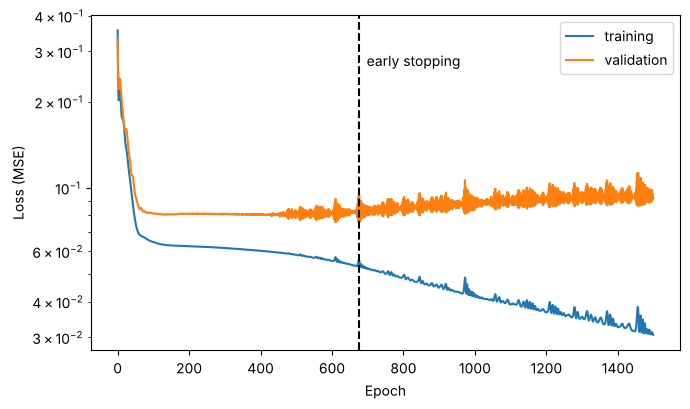

In [12]:
# Example 1.11: Error curve versus epoch and early stopping
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
 
rng = np.random.default_rng(0)
X = rng.uniform(-1, 1, (40, 1))
y = np.sin(3 * X).ravel() + rng.normal(0, 0.25, 40)
X_val = rng.uniform(-1, 1, (200, 1))
y_val = np.sin(3 * X_val).ravel() + rng.normal(0, 0.25, 200)
 
# A network deliberately larger than needed, so that overfitting occurs
net = MLPRegressor(hidden_layer_sizes=(200, 200), learning_rate_init=0.002,
                   alpha=0.0, random_state=1)
train_loss, val_loss = [], []
for epoch in range(1500):
    net.partial_fit(X, y)                     # one training epoch
    train_loss.append(mean_squared_error(y, net.predict(X)))
    val_loss.append(mean_squared_error(y_val, net.predict(X_val)))
 
best_epoch = int(np.argmin(val_loss))
print("Best epoch (minimum validation error):", best_epoch)
print("Validation MSE at best epoch:", round(val_loss[best_epoch], 4))
print("Validation MSE at last epoch:", round(val_loss[-1], 4))
print("Train MSE at last epoch:", round(train_loss[-1], 4))
 
plt.figure(figsize=(7, 4.2))
plt.plot(train_loss, label="training")
plt.plot(val_loss, label="validation")
plt.axvline(best_epoch, ls="--", c="k")
plt.text(best_epoch, max(val_loss) * 0.8, "  early stopping")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Loss (MSE)")
plt.legend(); plt.tight_layout(); plt.savefig("fig1_6.png", dpi=300)
 
# In practice, sklearn does this automatically:
auto = MLPRegressor(hidden_layer_sizes=(200, 200), early_stopping=True,
                    validation_fraction=0.2, n_iter_no_change=20,
                    max_iter=2000, random_state=1).fit(X, y)
print("sklearn early_stopping stopped after", auto.n_iter_, "epochs")